# Customer Review Text Analysis – Home Appliances
**Goal:** find out why ratings have slipped and which complaint themes product teams should fix first.

Pipeline: load data → clean (NLTK) → VADER sentiment + validation → LDA topics (coherence-tuned) → combine topics, sentiment, ratings and time → manual-label validation + supervised classifier → export tables and charts.

Run the cells top to bottom in Google Colab. All outputs are written to `/content/outputs`.

## 1. Setup

In [15]:
!pip -q install gensim langdetect wordcloud emoji
import nltk
for p in ['punkt', 'punkt_tab', 'stopwords', 'wordnet', 'omw-1.4', 'vader_lexicon']:
    nltk.download(p, quiet=True)
import os
os.makedirs('/content/outputs', exist_ok=True)
SEED = 42

## 2. Load data
Public dataset: **Amazon Reviews 2023 (McAuley Lab), Appliances category**, which has star ratings, timestamps and product IDs (`parent_asin`).
The file is large, so we stream the first 300,000 reviews and draw a random sample of 5,000.
If the download fails, run the fallback cell and upload any CSV with the columns `rating`, `text`, `date`, `product_id`.

In [16]:
import gzip, json, urllib.request
import pandas as pd, numpy as np

URL = "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_2023/raw/review_categories/Appliances.jsonl.gz"
N_SCAN, N_SAMPLE = 300_000, 5000

def load_amazon():
    rows = []
    with urllib.request.urlopen(URL, timeout=60) as r, gzip.GzipFile(fileobj=r) as gz:
        for i, line in enumerate(gz):
            if i >= N_SCAN:
                break
            d = json.loads(line)
            rows.append((d['rating'], d.get('title', ''), d.get('text', ''), d['parent_asin'], d['timestamp']))
    out = pd.DataFrame(rows, columns=['rating', 'title', 'body', 'product_id', 'ts'])
    out['text'] = (out['title'].fillna('') + '. ' + out['body'].fillna('')).str.strip('. ')
    out['date'] = pd.to_datetime(out['ts'], unit='ms')
    return out[['rating', 'text', 'date', 'product_id']]

try:
    pool = load_amazon()
    print('Streamed', len(pool), 'reviews')
except Exception as e:
    pool = None
    print('Download failed:', e, '\nRun the fallback cell below.')

Streamed 300000 reviews


In [17]:
# FALLBACK: only run if the cell above failed
if pool is None:
    from google.colab import files
    up = files.upload()
    pool = pd.read_csv(list(up.keys())[0], parse_dates=['date'])

In [18]:
raw = pool.sample(min(N_SAMPLE, len(pool)), random_state=SEED).reset_index(drop=True)
raw['review_id'] = raw.index
print(raw.shape)
print('Date range:', raw.date.min().date(), 'to', raw.date.max().date())
print(raw.rating.value_counts().sort_index())
raw.head()

(5000, 5)
Date range: 2006-04-07 to 2023-03-25
rating
1.0     423
2.0     152
3.0     259
4.0     539
5.0    3627
Name: count, dtype: int64


,rating,text,date,product_id,review_id
0,5.0,Saved the day. We installed this and fixed our washer. We thought the washer was DOA b...,2021-12-17 03:28:08.224,B09M3K5LV8,0
1,5.0,"Great product. Great product, didn’t notice any difference in taste vs original filter...",2019-06-25 18:47:16.430,B0C7GLWSJN,1
2,5.0,Works well!. Easy to use and has a good scent! Keeps mold and bacteria away!,2022-04-07 18:01:54.160,B079T4XXQY,2
3,5.0,Five star. Five star,2018-11-18 22:58:26.964,B00X52S6YC,3
4,5.0,It works. Installed it myself. Works great,2019-06-11 23:53:11.618,B00GS3T608,4


## 3. Cleaning pipeline
Steps (each removal is logged): emoji/URL/HTML removal and normalisation → drop very short reviews → drop duplicates → drop spam-like reviews → drop non-English → tokenise → domain-tuned stop words → lemmatise.

In [19]:
import re, emoji
from langdetect import detect, DetectorFactory
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
DetectorFactory.seed = SEED

df = raw.copy()
df['text_raw'] = df.text.fillna('').astype(str)
df['n_emoji'] = df.text_raw.apply(emoji.emoji_count)
log = [('Start', len(df))]

def normalise(t):
    t = t.replace('\u2019', "'")
    t = emoji.replace_emoji(t, ' ')
    t = re.sub(r'http\S+|www\.\S+', ' ', t)
    t = re.sub(r'<[^>]+>', ' ', t)
    t = t.lower()
    t = re.sub(r'(.)\1{2,}', r'\1\1', t)            # soooo -> soo
    t = t.replace("won't", 'will not').replace("can't", 'can not')
    t = re.sub(r"n't\b", ' not', t)
    t = re.sub(r'[^a-z\s]', ' ', t)
    return re.sub(r'\s+', ' ', t).strip()

df['norm'] = df.text_raw.apply(normalise)
df['n_words'] = df.norm.str.split().str.len()

# 1) very short entries
df = df[df.n_words >= 5]; log.append(('Removed very short (<5 words)', len(df)))

# 2) duplicates (same normalised text)
df = df.drop_duplicates('norm'); log.append(('Removed duplicate reviews', len(df)))

# 3) spam-like: URLs, very low lexical diversity, mostly capitals
def is_spam(row):
    raw_t, words = row.text_raw, row.norm.split()
    if re.search(r'http|www\.', raw_t): return True
    if len(words) >= 8 and len(set(words)) / len(words) < 0.4: return True
    letters = [c for c in raw_t if c.isalpha()]
    if len(letters) > 30 and sum(c.isupper() for c in letters) / len(letters) > 0.7: return True
    return False
df = df[~df.apply(is_spam, axis=1)]; log.append(('Removed spam-like', len(df)))

# 4) non-English
def lang(t):
    try: return detect(t)
    except Exception: return 'unk'
df['lang'] = df.norm.apply(lang)
df = df[df.lang == 'en']; log.append(('Removed non-English', len(df)))

# 5) tokenise, domain stop words, lemmatise
STOP = set(stopwords.words('english')) - {'no', 'not', 'nor', 'never'}   # keep negations
DOMAIN = {'amazon', 'product', 'item', 'one', 'would', 'could', 'get', 'got', 'also', 'really', 'like',
          'buy', 'bought', 'purchase', 'purchased', 'order', 'ordered', 'review', 'star', 'stars',
          'just', 'even', 'thing', 'much', 'well', 'good', 'great', 'ok', 'okay', 'use', 'used', 'using', 'will'}
lem = WordNetLemmatizer()
def tokens(t):
    out = []
    for w in word_tokenize(t):
        if len(w) < 3 or w in STOP or w in DOMAIN: continue
        out.append(lem.lemmatize(lem.lemmatize(w, 'v'), 'n'))
    return out
df['tokens'] = df.norm.apply(tokens)
df = df[df.tokens.str.len() >= 3].reset_index(drop=True)
log.append(('Removed reviews with <3 tokens after cleaning', len(df)))

pd.DataFrame(log, columns=['step', 'reviews_remaining']).to_csv('/content/outputs/cleaning_log.csv', index=False)
print(pd.DataFrame(log, columns=['step', 'reviews_remaining']))
print('Reviews containing emoji (before removal):', int((df.n_emoji > 0).sum()))
df[['text_raw', 'tokens']].head(3)

                                            step  reviews_remaining
0                                          Start               5000
1                  Removed very short (<5 words)               4618
2                      Removed duplicate reviews               4599
3                              Removed spam-like               4570
4                            Removed non-English               4471
5  Removed reviews with <3 tokens after cleaning               4363
Reviews containing emoji (before removal): 41


,text_raw,tokens
0,Saved the day. We installed this and fixed our washer. We thought the washer was DOA b...,"[save, day, instal, fix, washer, think, washer, doa, dollar, work]"
1,"Great product. Great product, didn’t notice any difference in taste vs original filter...","[not, notice, difference, taste, original, filter, cost]"
2,Works well!. Easy to use and has a good scent! Keeps mold and bacteria away!,"[work, easy, scent, keep, mold, bacteria, away]"


## 4. Sentiment with VADER, validated against star ratings
VADER is run on the **raw** text (it understands capitals, punctuation and emoji). Ratings are mapped to positive (4–5), neutral (3), negative (1–2).

              precision    recall  f1-score   support

    negative      0.487     0.534     0.510       543
     neutral      0.110     0.139     0.123       244
    positive      0.907     0.877     0.892      3576

    accuracy                          0.793      4363
   macro avg      0.501     0.517     0.508      4363
weighted avg      0.810     0.793     0.801      4363

                 vader_negative  vader_neutral  vader_positive
rating_negative             290             61             192
rating_neutral               79             34             131
rating_positive             226            213            3137

Spearman correlation (stars vs VADER compound): 0.423

Strong disagreement rate overall: 0.096
Disagreement rate when review has a contrast word (but/however...): 0.158
Disagreement rate without contrast word: 0.075
Share of 1-2 star reviews with praise words (possible sarcasm / mixed): 0.092

### Positive stars but VADER negative
 - do not fit. to small to fit st

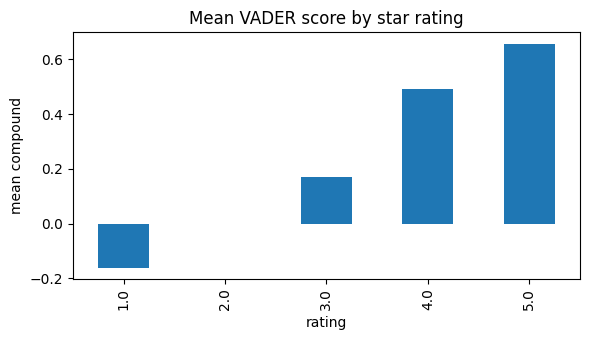

In [20]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from sklearn.metrics import classification_report, confusion_matrix
from scipy.stats import spearmanr
import matplotlib.pyplot as plt

sia = SentimentIntensityAnalyzer()
df['vader'] = df.text_raw.apply(lambda t: sia.polarity_scores(t)['compound'])
df['vader_label'] = df.vader.apply(lambda c: 'positive' if c >= 0.05 else ('negative' if c <= -0.05 else 'neutral'))
df['rating_label'] = df.rating.apply(lambda r: 'positive' if r >= 4 else ('negative' if r <= 2 else 'neutral'))

labels = ['negative', 'neutral', 'positive']
print(classification_report(df.rating_label, df.vader_label, labels=labels, digits=3))
cm = pd.DataFrame(confusion_matrix(df.rating_label, df.vader_label, labels=labels),
                  index=['rating_' + l for l in labels], columns=['vader_' + l for l in labels])
print(cm)
rho, pval = spearmanr(df.rating, df.vader)
print(f'\nSpearman correlation (stars vs VADER compound): {rho:.3f}')

# Where and why do they disagree?
df['disagree'] = ((df.rating_label == 'positive') & (df.vader_label == 'negative')) | \
                 ((df.rating_label == 'negative') & (df.vader_label == 'positive'))
df['mixed_cue'] = df.norm.str.contains(r'\b(?:but|however|although|except|unfortunately)\b')
df['sarcasm_cue'] = (df.rating <= 2) & df.norm.str.contains(r'\b(?:great|love|perfect|thanks|wonderful|amazing)\b')
print('\nStrong disagreement rate overall:', round(df.disagree.mean(), 3))
print('Disagreement rate when review has a contrast word (but/however...):', round(df[df.mixed_cue].disagree.mean(), 3))
print('Disagreement rate without contrast word:', round(df[~df.mixed_cue].disagree.mean(), 3))
print('Share of 1-2 star reviews with praise words (possible sarcasm / mixed):', round(df[df.rating <= 2].sarcasm_cue.mean(), 3))

for name, mask in [('Positive stars but VADER negative', (df.rating_label == 'positive') & (df.vader_label == 'negative')),
                   ('Negative stars but VADER positive', (df.rating_label == 'negative') & (df.vader_label == 'positive'))]:
    print('\n###', name)
    for t in df[mask].text_raw.head(4): print(' -', t[:220].replace('\n', ' '))

df.groupby('rating').vader.mean().plot(kind='bar', title='Mean VADER score by star rating', figsize=(6, 3.5))
plt.ylabel('mean compound'); plt.tight_layout(); plt.savefig('/content/outputs/vader_by_rating.png', dpi=150); plt.show()

## 5. Topic modelling with LDA
The number of topics is chosen by the **c_v coherence score** (target > 0.45). Bigrams are added so phrases such as `stop_working` stay together; words in more than 40% of reviews or fewer than 10 are dropped.

Vocabulary size: 2144 | documents: 4363
k= 3  coherence=0.4249
k= 4  coherence=0.4102
k= 5  coherence=0.4658
k= 6  coherence=0.4050
k= 7  coherence=0.3973
k= 8  coherence=0.4289
k= 9  coherence=0.3895
k=10  coherence=0.4113
k=11  coherence=0.4072
k=12  coherence=0.3795


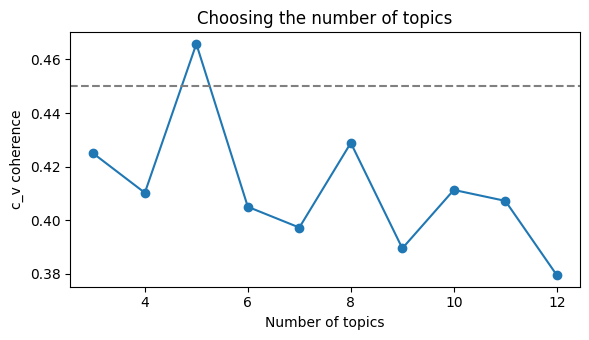


Selected k=5 with coherence 0.4658  ->  target >0.45 met: True


In [21]:
from gensim.corpora import Dictionary
from gensim.models import LdaModel, CoherenceModel, Phrases

docs = df.tokens.tolist()
bigram = Phrases(docs, min_count=3, threshold=5)
docs = [bigram[d] for d in docs]
dictionary = Dictionary(docs)
dictionary.filter_extremes(no_below=5, no_above=0.5)
corpus = [dictionary.doc2bow(d) for d in docs]
print('Vocabulary size:', len(dictionary), '| documents:', len(corpus))

results = []
for k in range(3, 13):
    m = LdaModel(corpus, id2word=dictionary, num_topics=k, passes=20, iterations=200,
                 alpha='auto', random_state=SEED, eval_every=None)
    coh = CoherenceModel(model=m, texts=docs, dictionary=dictionary, coherence='c_v', processes=1).get_coherence()
    results.append((k, coh, m)); print(f'k={k:2d}  coherence={coh:.4f}')

coh_df = pd.DataFrame([(k, c) for k, c, _ in results], columns=['num_topics', 'coherence'])
coh_df.to_csv('/content/outputs/coherence_scores.csv', index=False)
plt.figure(figsize=(6, 3.5)); plt.plot(coh_df.num_topics, coh_df.coherence, marker='o')
plt.axhline(0.45, ls='--', c='grey'); plt.xlabel('Number of topics'); plt.ylabel('c_v coherence')
plt.title('Choosing the number of topics'); plt.tight_layout()
plt.savefig('/content/outputs/coherence_plot.png', dpi=150); plt.show()

K_OVERRIDE = None   # set an int here to force a number of topics
best_k, best_coh, lda = max(results, key=lambda x: x[1]) if K_OVERRIDE is None else [r for r in results if r[0] == K_OVERRIDE][0]
print(f'\nSelected k={best_k} with coherence {best_coh:.4f}  ->  target >0.45 met: {best_coh > 0.45}')

In [22]:
K = best_k
theta = np.zeros((len(corpus), K))
for i, bow in enumerate(corpus):
    for t, p in lda.get_document_topics(bow, minimum_probability=0):
        theta[i, t] = p
df['topic'] = theta.argmax(1)
df['topic_p'] = theta.max(1)

for t in range(K):
    words = ', '.join(w for w, _ in lda.show_topic(t, topn=10))
    print(f'\n=== Topic {t}  ({(df.topic == t).sum()} reviews) ===\nTop words: {words}')
    for idx in np.argsort(-theta[:, t])[:3]:
        print('  *', df.text_raw[idx][:200].replace('\n', ' '), f'  [rating {df.rating[idx]}]')


=== Topic 0  (500 reviews) ===
Top words: not, fit, look, stave, top, need, make, perfect, two, burner
  * Dented. Hard to see clearly from the pictures but the top corner is smashed & the bottom is dented in. I am updating my review from 2-4 stars because I went to return it & Upstreman customer service d   [rating 4.0]
  * Doesn’t work believe it or not:-). Door slides too easy, the vibration from the dishwasher causes the door to move thus making it useless.<br />Looks pretty but not functional   [rating 1.0]
  * Easy to trim, fits well. Got a set of these to fill the gap between my stove and counter and it does a great job. Considering the amount of stuff that gets cleaned off them, that would otherwise be do   [rating 5.0]

=== Topic 1  (644 reviews) ===
Top words: not, machine, clean, come, water, say, dishwasher, back, put, washer
  * Works great. I saw a ton of videos on this unit before I bought it. I was worried about noise level and if it really cleans your clothes. Needles

### Label the topics
Read the output above and write a short business label for each topic number. Edit the dictionary below, then run the next cells. Use unique labels.

In [23]:
TOPIC_LABELS = {
    0: "Product Fit and Stove Accessories",
    1: "Washing and Cleaning Performance",
    2: "Replacement Parts and Installation",
    3: "Ice Maker and Freezer Performance",
    4: "Coffee Filters and Brewing Quality"
}

df['theme'] = df.topic.map(TOPIC_LABELS)
print(TOPIC_LABELS)


{0: 'Product Fit and Stove Accessories', 1: 'Washing and Cleaning Performance', 2: 'Replacement Parts and Installation', 3: 'Ice Maker and Freezer Performance', 4: 'Coffee Filters and Brewing Quality'}


## 6. Combine topics, sentiment, ratings and time → rank complaint themes

In [24]:
df['year'] = df.date.dt.year
df['neg'] = (df.rating <= 2).astype(int)

def neg_trend(g):
    yr = g.groupby('year').agg(n=('neg', 'size'), neg=('neg', 'mean'))
    yr = yr[yr.n >= 20]
    return np.polyfit(yr.index, yr.neg, 1)[0] if len(yr) >= 3 else np.nan   # change in negative share per year

rows = []
for t in range(K):
    g = df[df.topic == t]
    rows.append(dict(theme=TOPIC_LABELS[t], reviews=len(g), share_of_reviews=len(g) / len(df),
                     mean_rating=g.rating.mean(), mean_vader=g.vader.mean(),
                     negative_share=g.neg.mean(), neg_trend_per_year=neg_trend(g)))
summary = pd.DataFrame(rows)
summary['priority_score'] = summary.share_of_reviews * summary.negative_share
summary = summary.sort_values('priority_score', ascending=False).reset_index(drop=True)
summary['priority_rank'] = summary.index + 1

def quote(theme):
    g = df[(df.theme == theme) & (df.rating <= 2)].sort_values('topic_p', ascending=False)
    if g.empty: g = df[df.theme == theme].sort_values('topic_p', ascending=False)
    return g.text_raw.iloc[0][:220].replace('\n', ' ')
summary['example_quote'] = summary.theme.apply(quote)
summary.round(3).to_csv('/content/outputs/theme_summary_table.csv', index=False)
pd.set_option('display.max_colwidth', 90)
summary.round(3)

,theme,reviews,share_of_reviews,mean_rating,mean_vader,negative_share,neg_trend_per_year,priority_score,priority_rank,example_quote
0,Washing and Cleaning Performance,644,0.148,3.443,0.280,0.318,0.014,0.047,1,"don't be stupid and buy this. I did not purchase on Amazon, but from Lowes but if anyo..."
1,Product Fit and Stove Accessories,500,0.115,3.864,0.426,0.208,0.003,0.024,2,"Doesn’t work believe it or not:-). Door slides too easy, the vibration from the dishwa..."
2,Coffee Filters and Brewing Quality,908,0.208,4.398,0.581,0.105,0.004,0.022,3,"Don't buy, unless you like weak coffee. I ordered this reusable carafe k cup since bot..."
3,Replacement Parts and Installation,1878,0.430,4.671,0.578,0.049,0.007,0.021,4,Save your money and buy a better element replacement. Perfect quality and fast shippin...
4,Ice Maker and Freezer Performance,433,0.099,4.395,0.563,0.109,0.010,0.011,5,The one I return. I ended up with two of these I’m not sure but the one that I install...


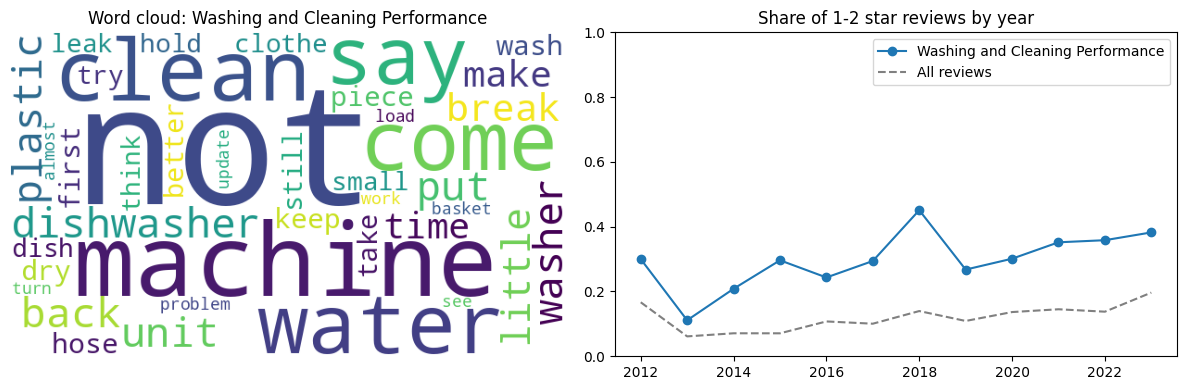

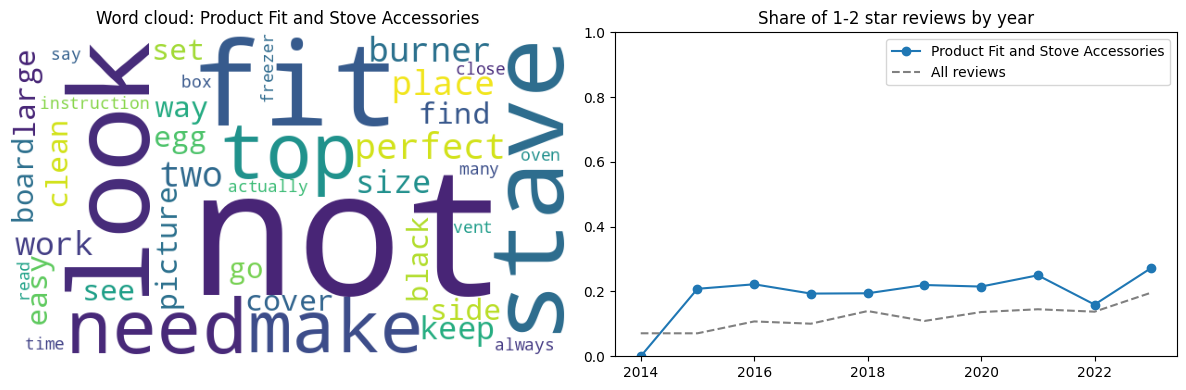

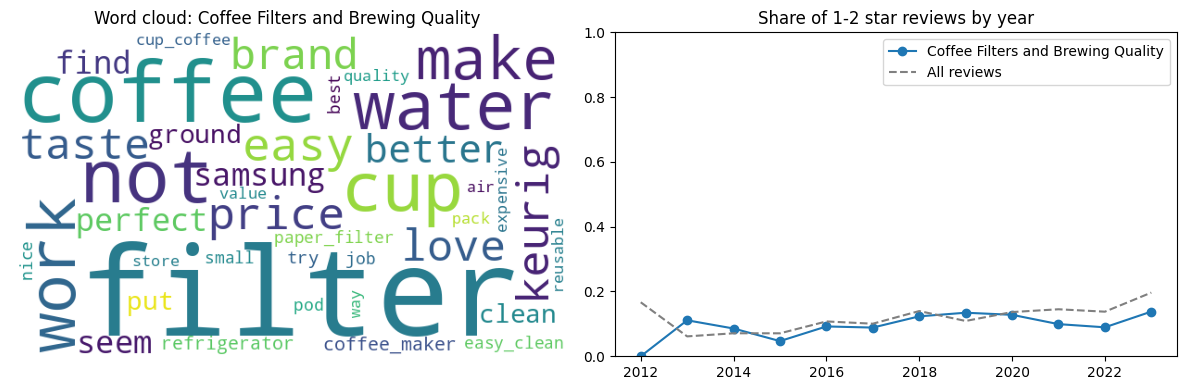

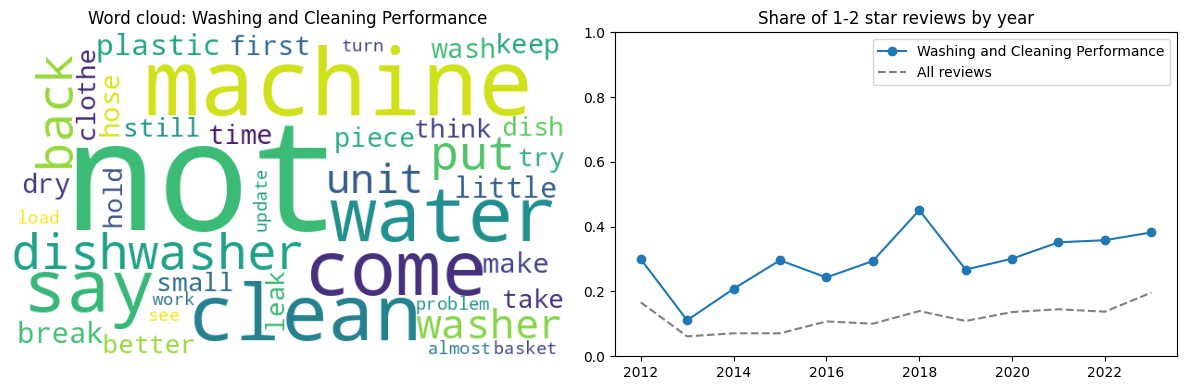

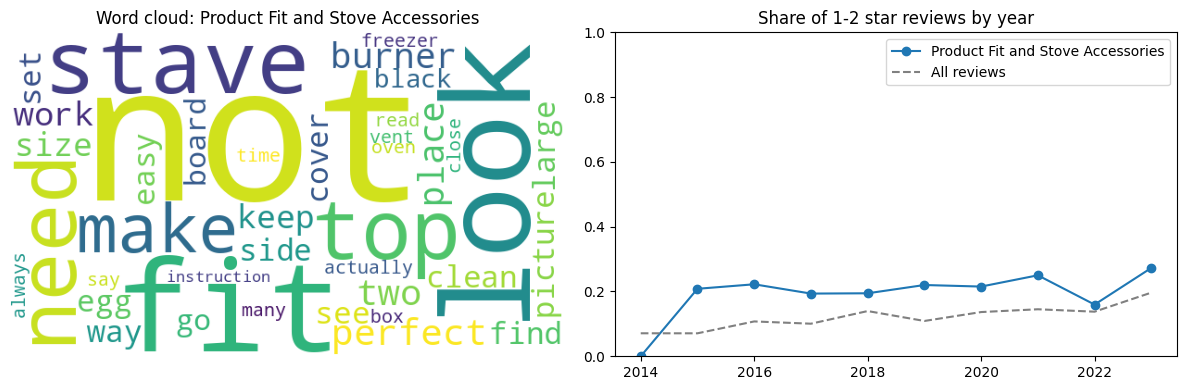

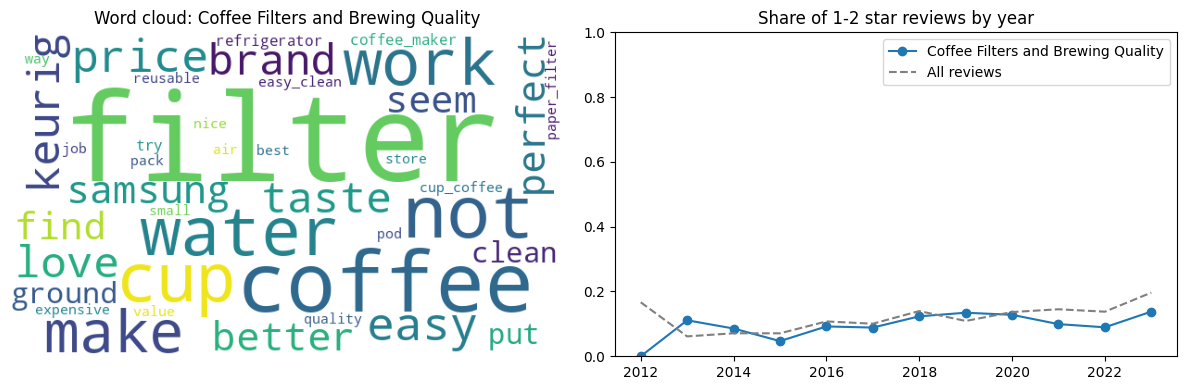

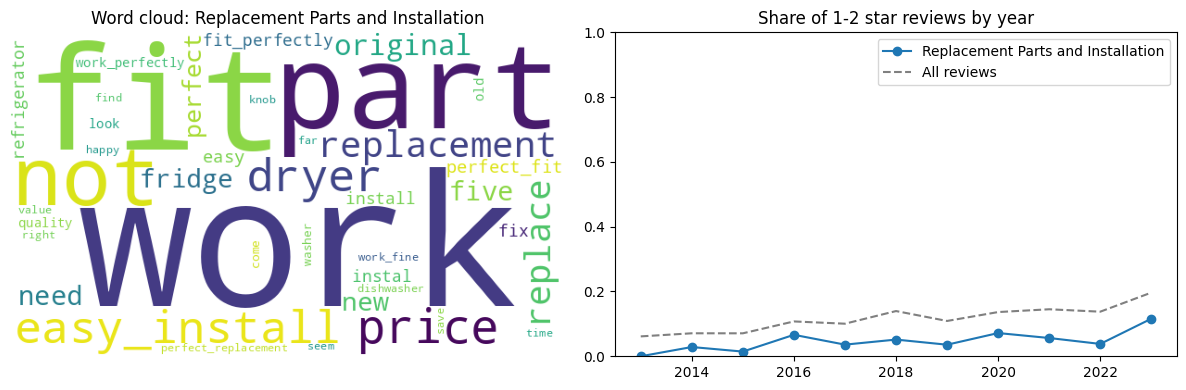

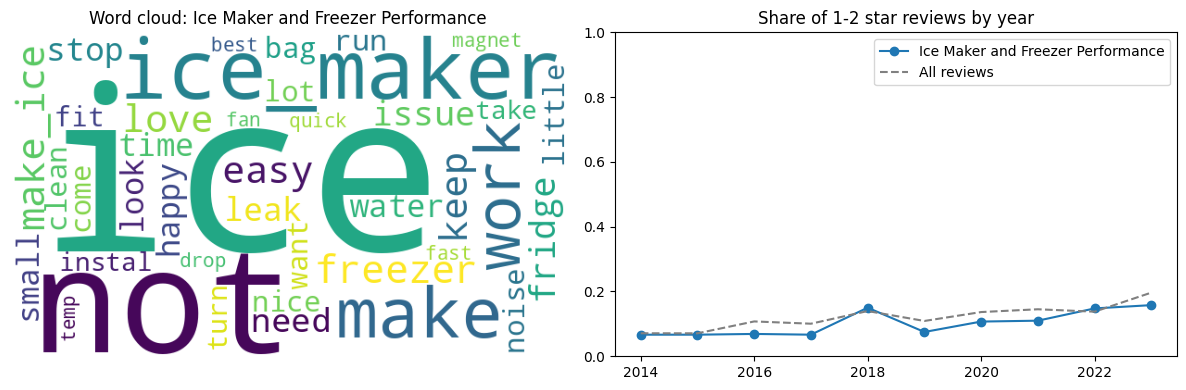

In [27]:
from wordcloud import WordCloud
top_themes = summary.theme.tolist()
inv = {v: k for k, v in TOPIC_LABELS.items()}

for th in top_themes:
    t = inv[th]
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    freqs = dict(lda.show_topic(t, topn=40))
    ax[0].imshow(WordCloud(width=600, height=350, background_color='white').generate_from_frequencies(freqs))
    ax[0].axis('off'); ax[0].set_title(f'Word cloud: {th}')
    g = df[df.theme == th]; allg = df
    yr = g.groupby('year').agg(n=('neg', 'size'), neg=('neg', 'mean')); yr = yr[yr.n >= 10]
    base = allg.groupby('year').neg.mean().reindex(yr.index)
    ax[1].plot(yr.index, yr.neg, marker='o', label=th); ax[1].plot(yr.index, base, ls='--', c='grey', label='All reviews')
    ax[1].set_title('Share of 1-2 star reviews by year'); ax[1].set_ylim(0, 1); ax[1].legend()
    plt.tight_layout()
    plt.savefig('/content/outputs/theme_' + re.sub(r'\W+', '_', th) + '.png', dpi=150); plt.show()

## 7. Validation: manual labelling and supervised classifier (stretch)
1. Run the export cell: it saves 300 random reviews **without** the model's topic, so your labels are unbiased.
2. Open `manual_labelling_sample.csv` in Excel/Sheets. In `human_theme`, type exactly one of the theme labels printed below (or `Other`) for every review. Row 1–100 form the held-out set for the agreement target (≥ 75%).
3. Upload the filled file and run the evaluation cell.

In [26]:
sample = df.sample(300, random_state=1)[['review_id', 'text_raw']].copy()
sample['human_theme'] = ''
sample.to_csv('/content/outputs/manual_labelling_sample.csv', index=False)
print('Allowed labels:', list(TOPIC_LABELS.values()) + ['Other'])
from google.colab import files
files.download('/content/outputs/manual_labelling_sample.csv')

Allowed labels: ['Product Fit and Stove Accessories', 'Washing and Cleaning Performance', 'Replacement Parts and Installation', 'Ice Maker and Freezer Performance', 'Coffee Filters and Brewing Quality', 'Other']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [13]:
# After labelling, upload the filled CSV here
from google.colab import files
up = files.upload()
lab = pd.read_csv(list(up.keys())[0]).dropna(subset=['human_theme'])
lab = lab.merge(df[['review_id', 'theme', 'norm']], on='review_id')
lab['human_theme'] = lab.human_theme.str.strip()

held = lab.head(100)
agree_100 = (held.human_theme == held.theme).mean()
agree_all = (lab.human_theme == lab.theme).mean()
print(f'LDA theme vs human label agreement: held-out first 100 = {agree_100:.1%} (target >= 75%) | all {len(lab)} = {agree_all:.1%}')

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import accuracy_score
pipe = make_pipeline(
    TfidfVectorizer(
        analyzer='char_wb',
        ngram_range=(3, 5),
        min_df=2,
        sublinear_tf=True
    ),
    LogisticRegression(
        max_iter=2000,
        class_weight='balanced',
        random_state=42
    )
)
n_min = lab.human_theme.value_counts().min()
cv = StratifiedKFold(n_splits=min(5, max(2, n_min)), shuffle=True, random_state=SEED)
pred = cross_val_predict(pipe, lab.norm, lab.human_theme, cv=cv)
print(f'Supervised TF-IDF + Logistic Regression, cross-validated accuracy on {len(lab)} labelled reviews: {accuracy_score(lab.human_theme, pred):.1%}')
print(classification_report(lab.human_theme, pred, zero_division=0))

Saving manual_labelling_reviewed.csv to manual_labelling_reviewed.csv
LDA theme vs human label agreement: held-out first 100 = 50.0% (target >= 75%) | all 300 = 46.7%
Supervised TF-IDF + Logistic Regression, cross-validated accuracy on 300 labelled reviews: 72.7%
                                    precision    recall  f1-score   support

Coffee Filters and Brewing Quality       0.95      0.88      0.91        41
 Ice Maker and Freezer Performance       0.78      0.58      0.67        12
                             Other       0.63      0.69      0.66        74
 Product Fit and Stove Accessories       0.59      0.46      0.52        28
Replacement Parts and Installation       0.77      0.77      0.77       123
  Washing and Cleaning Performance       0.62      0.73      0.67        22

                          accuracy                           0.73       300
                         macro avg       0.72      0.69      0.70       300
                      weighted avg       0.73     

## 8. Package outputs

In [28]:
import shutil
shutil.make_archive('/content/review_analysis_outputs', 'zip', '/content/outputs')
from google.colab import files
files.download('/content/review_analysis_outputs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>